In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

drive.mount('/content/drive')

DIR = f"/content/drive/My Drive/AIML Lab/Extra"

Mounted at /content/drive


In [ ]:
df = pd.read_csv(f"{DIR}/placement.csv")

df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(df[['cgpa']], df['package'], test_size=0.2, random_state=42)

linear = LinearRegression()

linear.fit(x_train, y_train)

y_pred = linear.predict(x_test)

print(f"Slope: {linear.coef_[0]}")
print(f"Intercept: {linear.intercept_}")

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error

print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred)}")
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, y_pred)}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")
print(f"R2 Error: {r2_score(y_test, y_pred)}")


Slope: 0.5742564727019197
Intercept: -1.0270069374542108
Mean Squared Error: 0.08417638361329656
Root Mean Squared Error: 0.2901316659954521
Mean Absolute Error: 0.23150985393278373
R2 Error: 0.7730984312051673


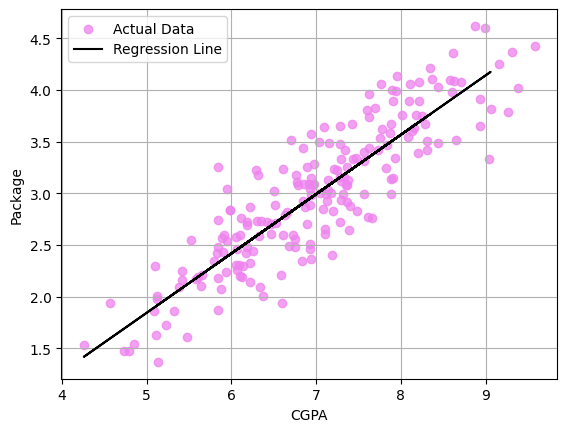

In [ ]:
plt.scatter(df['cgpa'], df['package'], color='violet', alpha=0.75, label='Actual Data')
plt.plot(x_test, y_pred, color='black', label='Regression Line')
plt.xlabel('CGPA')
plt.ylabel('Package')
plt.grid(True)
plt.legend()
plt.show()


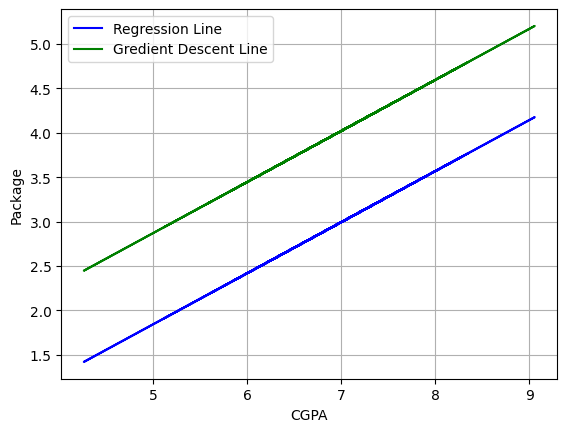

In [ ]:
beta = 0
learning_rate = 0.01

y_pred_gd = x_test * linear.coef_[0] + beta

plt.plot(x_test, y_pred, color='blue', label='Regression Line')
plt.plot(x_test, y_pred_gd, color='green', label='Gredient Descent Line')
plt.xlabel('CGPA')
plt.ylabel('Package')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Ensure we work with 1D numpy arrays to avoid pandas index alignment issues
y_arr = y_train.values
x_arr = x_train['cgpa'].values

# formula: -2/N * sum(y - (m*x + b))

slope = (-2/len(y_arr)) * np.sum(y_arr - (linear.coef_[0] * x_arr + beta))

print(slope)

9.941427154556761


In [ ]:
beta = beta - learning_rate * slope

print(beta)

3.8442923682786017


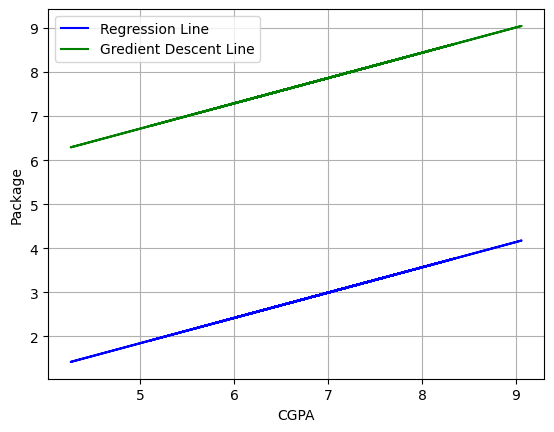

In [ ]:
y_pred_gd = x_test * linear.coef_[0] + beta

plt.plot(x_test, y_pred, color='blue', label='Regression Line')
plt.plot(x_test, y_pred_gd, color='green', label='Gredient Descent Line')
plt.xlabel('CGPA')
plt.ylabel('Package')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
slope = (-2/len(y_arr)) * np.sum(y_arr - (linear.coef_[0] * x_arr + beta))

print(slope)

9.742598611465626


In [ ]:
beta = beta - learning_rate * slope

print(beta)

3.746866382163945


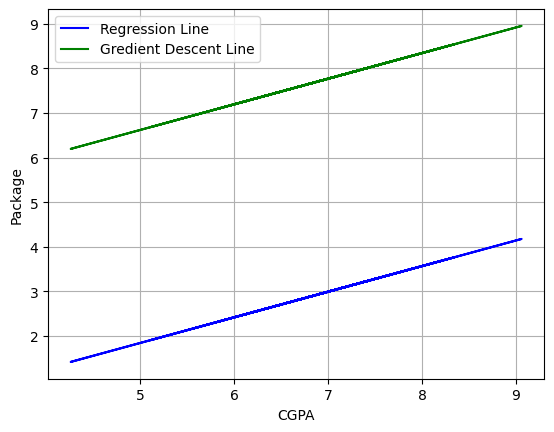

In [ ]:
y_pred_gd = x_test * linear.coef_[0] + beta

plt.plot(x_test, y_pred, color='blue', label='Regression Line')
plt.plot(x_test, y_pred_gd, color='green', label='Gredient Descent Line')
plt.xlabel('CGPA')
plt.ylabel('Package')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:

beta = 0.0
learning_rate = 0.01

x_arr = x_train["cgpa"].to_numpy()
y_arr = y_train.to_numpy()
m = linear.coef_[0]
n = len(y_arr)

for i in range(1000):

    y_hat = m * x_arr + beta

    gradient = (-2 / n) * np.sum(y_arr - y_hat)

    beta = beta - learning_rate * gradient

    if i % 100 == 0:
        print(f"Iteration {i}: beta = {beta:.4f}, gradient = {gradient:.4f}")

print("\nOLS intercept:", linear.intercept_)
print("Gradient Descent intercept:", beta)


Iteration 0: beta = -0.0205, gradient = 2.0540
Iteration 100: beta = -0.8935, gradient = 0.2724
Iteration 200: beta = -1.0093, gradient = 0.0361
Iteration 300: beta = -1.0247, gradient = 0.0048
Iteration 400: beta = -1.0267, gradient = 0.0006
Iteration 500: beta = -1.0270, gradient = 0.0001
Iteration 600: beta = -1.0270, gradient = 0.0000
Iteration 700: beta = -1.0270, gradient = 0.0000
Iteration 800: beta = -1.0270, gradient = 0.0000
Iteration 900: beta = -1.0270, gradient = 0.0000

OLS intercept: -1.0270069374542108
Gradient Descent intercept: -1.0270069357257916


In [ ]:
y_pred_gd = x_test * linear.coef_[0] + beta

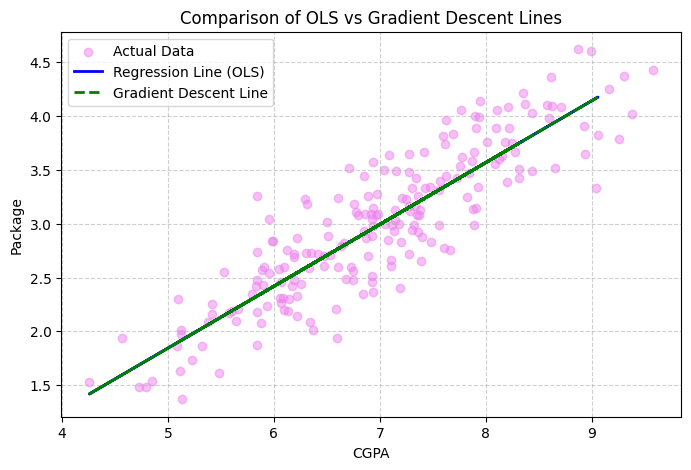

In [ ]:
# Plotting sorted lines
plt.figure(figsize=(8, 5))
plt.scatter(df['cgpa'], df['package'], color='violet', alpha=0.5, label='Actual Data')
plt.plot(x_test['cgpa'], y_pred, color='blue', linewidth=2, label='Regression Line (OLS)')
plt.plot(x_test['cgpa'], y_pred_gd, color='green', linewidth=2, linestyle='--', label='Gradient Descent Line')

plt.xlabel('CGPA')
plt.ylabel('Package')
plt.title('Comparison of OLS vs Gradient Descent Lines')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()